# Treinamento do Modelo

# Variáveis

In [19]:
input_dataset = '/home/icaro/git/p4-priority-queue/features-17-10-2026-00_51_55.csv'
test_datasets = ['/home/icaro/git/p4-priority-queue/features-17-10-2026-01_00_28.csv', '/home/icaro/git/p4-priority-queue/features-17-10-2026-03_19_48.csv']
output_dir = '/home/icaro/git/p4-priority-queue'
features = ['frame_size', 'ipi', 'tos', 'window']
model_parameters = {'max_depth': 10}

## Importando bibliotecas

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn as sk
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from scipy import stats

# Funções

In [3]:
def removeAtributoscomMesmoValor(dataset):

    dataset.drop(columns=dataset.columns[dataset.nunique()==1], inplace=True)

    return dataset

In [4]:
def removeOutliers(dataset):

    # detect and remove outliers
    z_scores = stats.zscore(dataset)
    abs_z_scores = np.abs(z_scores)
    filtered_entries = (abs_z_scores < 5).all(axis=1)
    dataset = dataset[filtered_entries]
    # reset index
    #dataset = dataset.reset_index(drop=True)

    return dataset

In [5]:
def removeDadosFaltantes(dataset):

    dataset=dataset.dropna()
    return dataset

In [6]:
def normalization(X):

    scaler = sk.preprocessing.StandardScaler().fit(X)
    X = scaler.transform(X)
    return X

In [7]:
def test_model(model, X, y, plot_matrix=False, img_name="confusion_matrix"):
  y_pred = model.predict(X)

  accuracy = accuracy_score(y, y_pred)
  precision = precision_score(y, y_pred, average="weighted")
  recall = recall_score(y, y_pred, average="weighted")
  f1 = f1_score(y, y_pred, average="weighted")

  cm = confusion_matrix(y, y_pred)

  # Display metrics
  print("\n" + "="*50)
  print("MODEL PERFORMANCE METRICS")
  print("="*50)
  print(f"Accuracy:  {accuracy:.4f}")
  print(f"Precision: {precision:.4f}")
  print(f"Recall:    {recall:.4f}")
  print(f"F1-Score:  {f1:.4f}")

  print("\n" + "="*50)
  print("DETAILED CLASSIFICATION REPORT")
  print("="*50)
  print(classification_report(y, y_pred))

  print("\n" + "="*50)
  print("CONFUSION MATRIX")
  print("="*50)
  print(cm)

  # Feature importance
  feature_importance = pd.DataFrame({
      'feature': X.columns,
      'importance': model.feature_importances_
  }).sort_values('importance', ascending=False)

  print("\n" + "="*50)
  print("FEATURE IMPORTANCE")
  print("="*50)
  print(feature_importance)

  if plot_matrix:
    # Plot confusion matrix
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=np.unique(y),
                yticklabels=np.unique(y))
    plt.title('Confusion Matrix')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.tight_layout()
    plt.savefig(f"{output_dir}/{img_name}.png", dpi=300, bbox_inches='tight')
    plt.show()

In [8]:
def n_test_model(model, datasets: list):
    for i,dataset in enumerate(datasets, 1):
        data = import_csv(dataset, True)
        Xt = data[features]
        yt = data[target]
        test_model(model, Xt, yt, True, f"confusion_matrix_test_data_{i}")

In [9]:
def import_csv(file, show_info=False):
  data = pd.read_csv(file)

  # data.dropna(subset=["flags"], inplace=True)

  # data = removeAtributoscomMesmoValor(data)
  data = removeDadosFaltantes(data)
  # data["IPI"] = removeOutliers(data["IPI"])

  if show_info:
    print("Info:")
    data.info()
    print("\nDescrição estatística:")
    print(data.describe())
    print("\nValores nulos:")
    print(data.isnull().sum())
    print("\nDistribuição da target:")
    print(data['classification'].value_counts())
    # print(data["Flags"].value_counts())

  return data

## Importação dos dados

In [10]:
data = import_csv(input_dataset, True)

Info:
<class 'pandas.DataFrame'>
RangeIndex: 51066 entries, 0 to 51065
Data columns (total 27 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   flow_key        51066 non-null  int64
 1   srcip           51066 non-null  str  
 2   dstip           51066 non-null  str  
 3   sport           51066 non-null  int64
 4   dport           51066 non-null  int64
 5   proto           51066 non-null  int64
 6   version         51066 non-null  int64
 7   ihl             51066 non-null  int64
 8   tos             51066 non-null  int64
 9   length          51066 non-null  int64
 10  id              51066 non-null  int64
 11  frag            51066 non-null  int64
 12  ttl             51066 non-null  int64
 13  chksum          51066 non-null  int64
 14  seq             51066 non-null  int64
 15  ack             51066 non-null  int64
 16  window          51066 non-null  int64
 17  dataofs         51066 non-null  int64
 18  urgptr          51066 non-null 

In [11]:
target = "classification"

X = data[features]
y = data[target]

# Treino do modelo

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
)

model = DecisionTreeClassifier(random_state=42, **model_parameters)
model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at

## Teste do modelo

### Com base de treinos


MODEL PERFORMANCE METRICS
Accuracy:  0.9594
Precision: 0.9598
Recall:    0.9594
F1-Score:  0.9594

DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     19285
           1       0.88      1.00      0.94      1482
           2       0.91      0.92      0.92      9191
           3       0.94      0.92      0.93     10894

    accuracy                           0.96     40852
   macro avg       0.93      0.96      0.94     40852
weighted avg       0.96      0.96      0.96     40852


CONFUSION MATRIX
[[19275     7     2     1]
 [    1  1481     0     0]
 [    1   107  8443   640]
 [    0    89   809  9996]]

FEATURE IMPORTANCE
      feature  importance
3      window    0.470978
2         tos    0.425263
0  frame_size    0.095481
1         ipi    0.008277


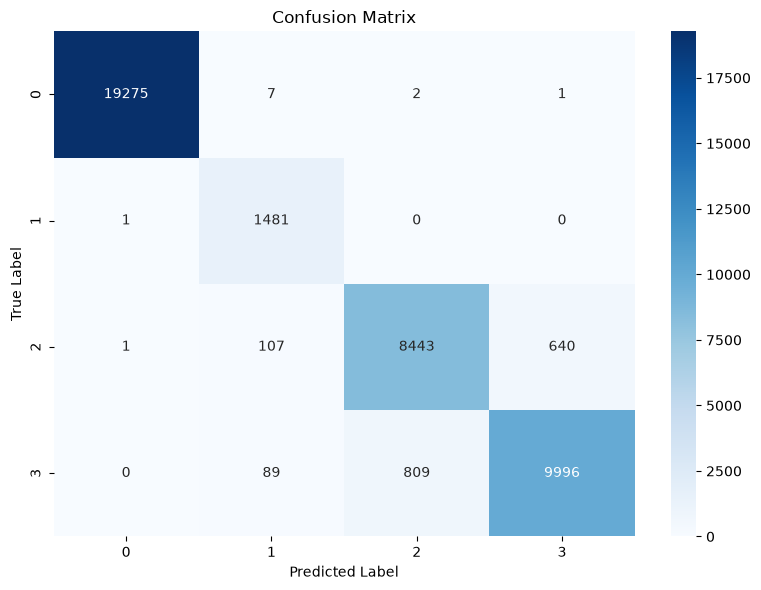

In [13]:
test_model(model, X_train, y_train, True, "confusion_matrix_train_data")

### Com base de validação


MODEL PERFORMANCE METRICS
Accuracy:  0.9583
Precision: 0.9587
Recall:    0.9583
F1-Score:  0.9583

DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4788
           1       0.88      1.00      0.93       368
           2       0.91      0.92      0.92      2366
           3       0.94      0.91      0.93      2692

    accuracy                           0.96     10214
   macro avg       0.93      0.96      0.94     10214
weighted avg       0.96      0.96      0.96     10214


CONFUSION MATRIX
[[4785    1    0    2]
 [   1  367    0    0]
 [   0   28 2187  151]
 [   0   22  221 2449]]

FEATURE IMPORTANCE
      feature  importance
3      window    0.470978
2         tos    0.425263
0  frame_size    0.095481
1         ipi    0.008277


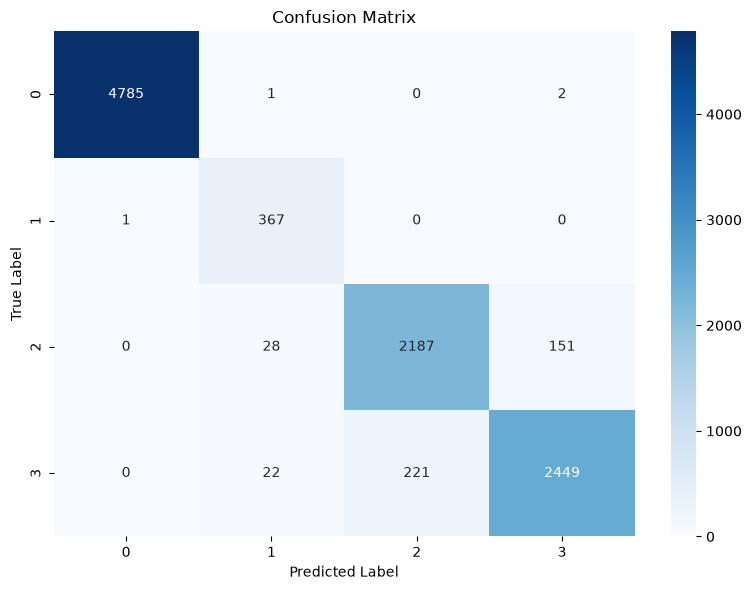

In [14]:
test_model(model, X_test, y_test, True, "confusion_matrix_validation_data")

### Com base de teste

Info:
<class 'pandas.DataFrame'>
RangeIndex: 51185 entries, 0 to 51184
Data columns (total 27 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   flow_key        51185 non-null  int64
 1   srcip           51185 non-null  str  
 2   dstip           51185 non-null  str  
 3   sport           51185 non-null  int64
 4   dport           51185 non-null  int64
 5   proto           51185 non-null  int64
 6   version         51185 non-null  int64
 7   ihl             51185 non-null  int64
 8   tos             51185 non-null  int64
 9   length          51185 non-null  int64
 10  id              51185 non-null  int64
 11  frag            51185 non-null  int64
 12  ttl             51185 non-null  int64
 13  chksum          51185 non-null  int64
 14  seq             51185 non-null  int64
 15  ack             51185 non-null  int64
 16  window          51185 non-null  int64
 17  dataofs         51185 non-null  int64
 18  urgptr          51185 non-null 

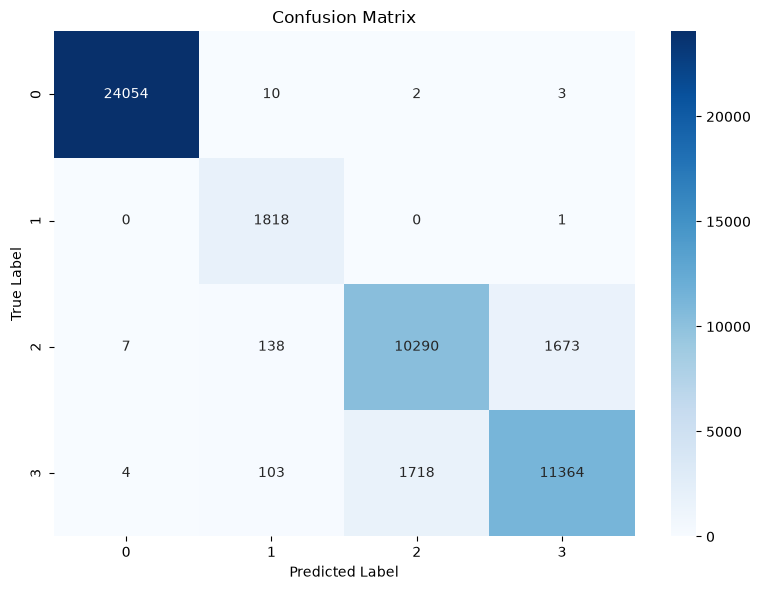

Info:
<class 'pandas.DataFrame'>
RangeIndex: 250479 entries, 0 to 250478
Data columns (total 27 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   flow_key        250479 non-null  int64
 1   srcip           250479 non-null  str  
 2   dstip           250479 non-null  str  
 3   sport           250479 non-null  int64
 4   dport           250479 non-null  int64
 5   proto           250479 non-null  int64
 6   version         250479 non-null  int64
 7   ihl             250479 non-null  int64
 8   tos             250479 non-null  int64
 9   length          250479 non-null  int64
 10  id              250479 non-null  int64
 11  frag            250479 non-null  int64
 12  ttl             250479 non-null  int64
 13  chksum          250479 non-null  int64
 14  seq             250479 non-null  int64
 15  ack             250479 non-null  int64
 16  window          250479 non-null  int64
 17  dataofs         250479 non-null  int64
 18  urgptr   

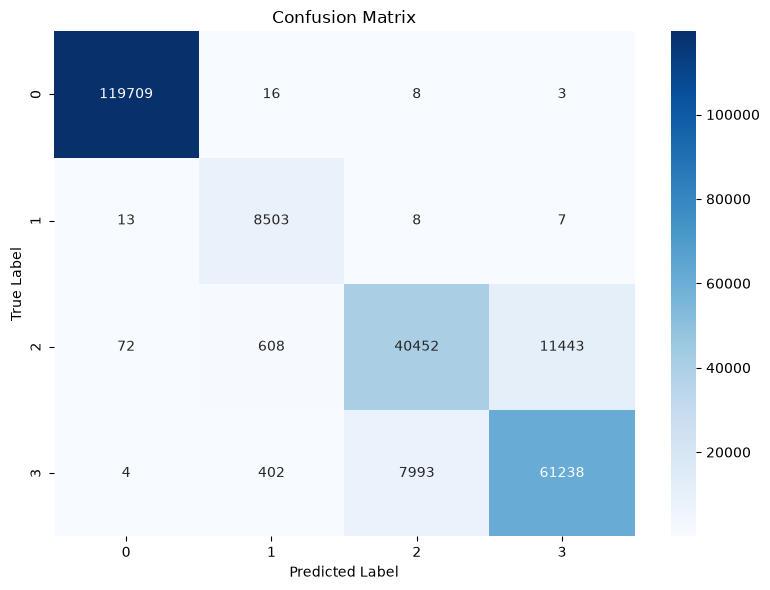

In [20]:
n_test_model(model, test_datasets)

# Exportar Modelo

In [16]:
import pickle

with open(f"{output_dir}/tree.pkl", "wb") as f:
  pickle.dump(model, f)